In [30]:
#Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.impute import SimpleImputer

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

In [31]:
# Load data
df = pd.read_csv("Electric Vehicle Population Data — 2026.csv")
df.shape

(289564, 16)

In [32]:
# Initial inspection
df.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,5UX43EU07S,Snohomish,Snohomish,WA,98296.0,2025,BMW,X5,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,40.0,44.0,279314360,POINT (-122.1389 47.87115),PUGET SOUND ENERGY INC,5.306105e+10
1,5YJ3E1EB5J,Yakima,Yakima,WA,98901.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215.0,14.0,220635992,POINT (-120.50729 46.60464),PACIFICORP,5.307700e+10
2,WA1AAAGE5M,King,Seattle,WA,98112.0,2021,AUDI,E-TRON,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,222.0,43.0,282112967,POINT (-122.30207 47.64085),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303301e+10
3,5YJXCAE2XG,Kitsap,Bremerton,WA,98310.0,2016,TESLA,MODEL X,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,200.0,23.0,103165100,POINT (-122.61136 47.5752),PUGET SOUND ENERGY INC,5.303508e+10
4,5YJ3E1EB5J,Yakima,Yakima,WA,98908.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215.0,14.0,301024209,POINT (-120.60272 46.59656),PACIFICORP,5.307700e+10


In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 289564 entries, 0 to 289563
Data columns (total 16 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         289564 non-null  str    
 1   County                                             289555 non-null  str    
 2   City                                               289555 non-null  str    
 3   State                                              289564 non-null  str    
 4   Postal Code                                        289555 non-null  float64
 5   Model Year                                         289564 non-null  int64  
 6   Make                                               289564 non-null  str    
 7   Model                                              289564 non-null  str    
 8   Electric Vehicle Type                              289564 non-null  str    
 9   Clea

In [34]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})

,missing_count,missing_pct
Legislative District,727,0.25
Vehicle Location,16,0.01
Electric Range,10,0.00
County,9,0.00
City,9,0.00
Postal Code,9,0.00
Electric Utility,9,0.00
2020 Census Tract,9,0.00
VIN (1-10),0,0.00
State,0,0.00


VIN (1-10) : First 10 characters of the vehicle identification number, used to identify the vehicle's make/model characteristics without exposing the full VIN

County: Washington county where the vehicle is registered.

City: City where the vehicle is registered.

State: State in which the vehicle is registered.

Postal Code: ZIP/postal code associated with the vehicle registration.

Model Year: Manufacturing/model year of the vehicle.

Make: Vehicle manufacturer/brand.

Model: Specific vehicle model.

Electric Vehicle Type: Type of electric vehicle, such as Battery Electric Vehicle (BEV) or Plug-in Hybrid Electric Vehicle (PHEV).

Clean Alternative Fuel Vehicle (CAFV) Eligibility: Indicates the vehicle's eligibility status under Washington's clean alternative fuel vehicle criteria.

Electric Range: EPA-rated electric driving range, generally measured in miles.

Legislative District: Washington State legislative district associated with the vehicle's registration location.

DOL Vehicle ID: Unique identifier assigned by the Washington Department of Licensing.

Vehicle Location: Geographic location associated with the vehicle registration, typically represented as a latitude/longitude-style value.

Electric Utility: Electric utility serving the vehicle's registered location.

In [35]:
# Data cleaning
df_clean = df.copy()
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

Rows: 289564
Columns: 16


In [36]:
df_clean = df_clean.rename(columns={
    "VIN (1-10)": "vin_10",
    "County": "county",
    "City": "city",
    "State": "state",
    "Postal Code": "postal_code",
    "Model Year": "model_year",
    "Make": "make",
    "Model": "model",
    "Electric Vehicle Type": "ev_type",
    "Clean Alternative Fuel Vehicle (CAFV) Eligibility": "cafv_eligibility",
    "Electric Range": "electric_range",
    "Legislative District": "legislative_district",
    "DOL Vehicle ID": "dol_vehicle_id",
    "Vehicle Location": "vehicle_location",
    "Electric Utility": "electric_utility",
    "2020 Census Tract": "census_tract"
})

In [37]:
df_clean.columns

Index(['vin_10', 'county', 'city', 'state', 'postal_code', 'model_year',
       'make', 'model', 'ev_type', 'cafv_eligibility', 'electric_range',
       'legislative_district', 'dol_vehicle_id', 'vehicle_location',
       'electric_utility', 'census_tract'],
      dtype='str')

In [38]:
# removing whitespaces
text_columns = df_clean.select_dtypes(include="object").columns
for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

/var/folders/vb/rvtgbc513wd4knzzjmsl970r0000gn/T/ipykernel_74438/538371110.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df_clean.select_dtypes(include="object").columns


In [39]:
print(df_clean["county"].value_counts().head(30))

county
King            140130
Snohomish        36508
Pierce           24162
Clark            18060
Thurston         10617
Kitsap           10023
Spokane           8329
Whatcom           7205
Benton            4304
Skagit            3440
Island            3164
Yakima            2109
Chelan            1914
Clallam           1819
Cowlitz           1610
Jefferson         1602
Mason             1540
Lewis             1333
San Juan          1332
Franklin          1320
Grant             1213
Grays Harbor      1153
Kittitas          1151
Walla Walla        833
Douglas            686
Whitman            595
Klickitat          529
Okanogan           464
Stevens            405
Pacific            369
Name: count, dtype: int64


In [40]:
exact_duplicates = df_clean.duplicated().sum()
vehicle_id_duplicates = df_clean["dol_vehicle_id"].duplicated().sum()
print("Exact duplicate rows:", exact_duplicates)
print("Duplicate DOL Vehicle IDs:", vehicle_id_duplicates)

Exact duplicate rows: 0
Duplicate DOL Vehicle IDs: 0


In [41]:
# Datatype correction: postal code should be treated as obj not int
df_clean["postal_code"] = (
    df_clean["postal_code"]
    .astype("Int64")
    .astype("string")
)

In [42]:
df_clean["legislative_district"] = (
    df_clean["legislative_district"]
    .astype("Int64")
)

In [43]:
df_clean["legislative_district"] = (
    df_clean["legislative_district"]
    .astype("Int64")
)

In [44]:
missing_summary = pd.DataFrame({
    "Missing Count": df_clean.isna().sum(),
    "Missing %": df_clean.isna().mean() * 100
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing %", ascending=False)

missing_summary

,Missing Count,Missing %
legislative_district,727,0.251067
vehicle_location,16,0.005526
electric_range,10,0.003453
county,9,0.003108
city,9,0.003108
postal_code,9,0.003108
electric_utility,9,0.003108
census_tract,9,0.003108


In [45]:
df_range = df_clean.dropna(subset=["electric_range"]).copy()

In [46]:
print(df_clean["model_year"].describe())

count    289564.000000
mean       2022.255957
std           3.080426
min        1999.000000
25%        2021.000000
50%        2023.000000
75%        2024.000000
max        2027.000000
Name: model_year, dtype: float64


In [47]:
df_clean[
    (df_clean["model_year"] < 1990) |
    (df_clean["model_year"] > 2030)
][["model_year", "make", "model"]]

,model_year,make,model


In [48]:
print(df_clean["electric_range"].describe())

count    289554.000000
mean         37.399770
std          76.741728
min           0.000000
25%           0.000000
50%           0.000000
75%          32.000000
max         337.000000
Name: electric_range, dtype: float64


In [49]:
df_clean[df_clean["electric_range"] == 0]

,vin_10,county,city,state,postal_code,model_year,make,model,ev_type,cafv_eligibility,electric_range,legislative_district,dol_vehicle_id,vehicle_location,electric_utility,census_tract
15,WB523CF0XR,Thurston,Rainier,WA,98576,2024,BMW,IX,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,2,262831579,POINT (-122.68993 46.88897),PUGET SOUND ENERGY INC,5.306701e+10
29,5YJYGDEF8M,Thurston,Olympia,WA,98516,2021,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,2,270138662,POINT (-122.78598 47.08476),PUGET SOUND ENERGY INC,5.306701e+10
32,KMTGE4S1XR,Yakima,Zillah,WA,98953,2024,GENESIS,G80,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,15,282155779,POINT (-120.26226 46.40199),PACIFICORP,5.307700e+10
46,1N4CZ1CVXP,Kitsap,Bremerton,WA,98337,2023,NISSAN,LEAF,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,26,276884898,POINT (-122.62749 47.565),PUGET SOUND ENERGY INC,5.303508e+10
48,3FMTK3SU3M,Yakima,Yakima,WA,98901,2021,FORD,MUSTANG MACH-E,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,15,148673591,POINT (-120.50729 46.60464),PACIFICORP,5.307700e+10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
289558,WB523CF05R,King,Covington,WA,98042,2024,BMW,IX,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,47,251851407,POINT (-122.10798 47.37124),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303303e+10
289559,3FMTK4SX2S,Clark,Las Vegas,NV,89119,2025,FORD,MUSTANG MACH-E,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,<NA>,287033484,POINT (-115.13452 36.1009),NON WASHINGTON STATE ELECTRIC UTILITY,3.200300e+10
289560,7YAKNDDC7S,King,Seattle,WA,98118,2025,HYUNDAI,IONIQ 5,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,37,282573343,POINT (-122.2668 47.55115),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303301e+10
289561,5YJ3E1ECXM,Clark,Vancouver,WA,98686,2021,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,17,291545649,POINT (-122.62731 45.71668),BONNEVILLE POWER ADMINISTRATION||PUD NO 1 OF C...,5.301104e+10


In [50]:
# Check zero electric-range records by EV type
zero_range_by_type = (
    df_clean[df_clean["electric_range"] == 0]
    ["ev_type"]
    .value_counts(dropna=False)
)

print(zero_range_by_type)

ev_type
Battery Electric Vehicle (BEV)    188456
Name: count, dtype: int64


In [51]:
df_clean["electric_range"] = df_clean["electric_range"].replace(0, np.nan)

0 values in electric range are due to washington state licensing dept deciding that 0 is for when electric range has not been researched for the vehicle. it specifically applies to BEVs.
As all the 0 values belong to BEVs, they have been amended to null.

In [52]:
df_clean["ev_type"].value_counts(dropna=False)

ev_type
Battery Electric Vehicle (BEV)            233544
Plug-in Hybrid Electric Vehicle (PHEV)     56020
Name: count, dtype: int64

In [53]:
df_clean["cafv_eligibility"].value_counts(dropna=False)

cafv_eligibility
Eligibility unknown as battery range has not been researched    188456
Clean Alternative Fuel Vehicle Eligible                          77580
Not eligible due to low battery range                            23528
Name: count, dtype: int64

In [54]:
df_clean["state"].value_counts(dropna=False)

state
WA    288838
CA       173
VA        91
FL        45
MD        42
TX        40
OR        27
CO        26
NV        24
NC        21
AZ        19
IL        19
NY        14
GA        14
MO        11
NJ         9
MI         9
MA         9
AL         9
DC         8
ID         7
RI         7
NE         7
SC         7
KY         6
PA         6
CT         6
TN         6
OH         5
NM         5
LA         5
WI         5
KS         4
NH         4
AE         3
IN         3
MN         3
BC         3
AR         2
SD         2
WY         2
HI         2
OK         2
AK         2
UT         2
ME         2
IA         2
MT         1
MS         1
QC         1
AP         1
GU         1
DE         1
Name: count, dtype: int64

In [55]:
df_clean["make"].nunique()
df_clean["make"].value_counts().head(20)

make
TESLA            118148
CHEVROLET         19808
NISSAN            16023
FORD              15930
KIA               14501
TOYOTA            13057
BMW               12024
HYUNDAI           11696
RIVIAN             9491
VOLKSWAGEN         7863
VOLVO              7791
AUDI               6033
JEEP               6028
CHRYSLER           3540
MERCEDES-BENZ      3430
HONDA              3340
SUBARU             3118
CADILLAC           2724
PORSCHE            2114
LEXUS              1987
Name: count, dtype: int64

In [56]:
# Observed EV demand = number of registered vehicles
manufacturer_demand = (
    df_clean.groupby("make")
    .size()
    .reset_index(name="vehicle_count")
    .sort_values("vehicle_count", ascending=False)
)
manufacturer_demand.head(10)

,make,vehicle_count
42,TESLA,118148
9,CHEVROLET,19808
34,NISSAN,16023
15,FORD,15930
22,KIA,14501
44,TOYOTA,13057
6,BMW,12024
19,HYUNDAI,11696
38,RIVIAN,9491
46,VOLKSWAGEN,7863


In [57]:
manufacturer_demand["market_share_pct"] = (
    manufacturer_demand["vehicle_count"]
    / manufacturer_demand["vehicle_count"].sum()
    * 100
)
manufacturer_demand.head(10)

,make,vehicle_count,market_share_pct
42,TESLA,118148,40.802033
9,CHEVROLET,19808,6.840629
34,NISSAN,16023,5.533492
15,FORD,15930,5.501374
22,KIA,14501,5.007874
44,TOYOTA,13057,4.509193
6,BMW,12024,4.152450
19,HYUNDAI,11696,4.039176
38,RIVIAN,9491,3.277686
46,VOLKSWAGEN,7863,2.715462


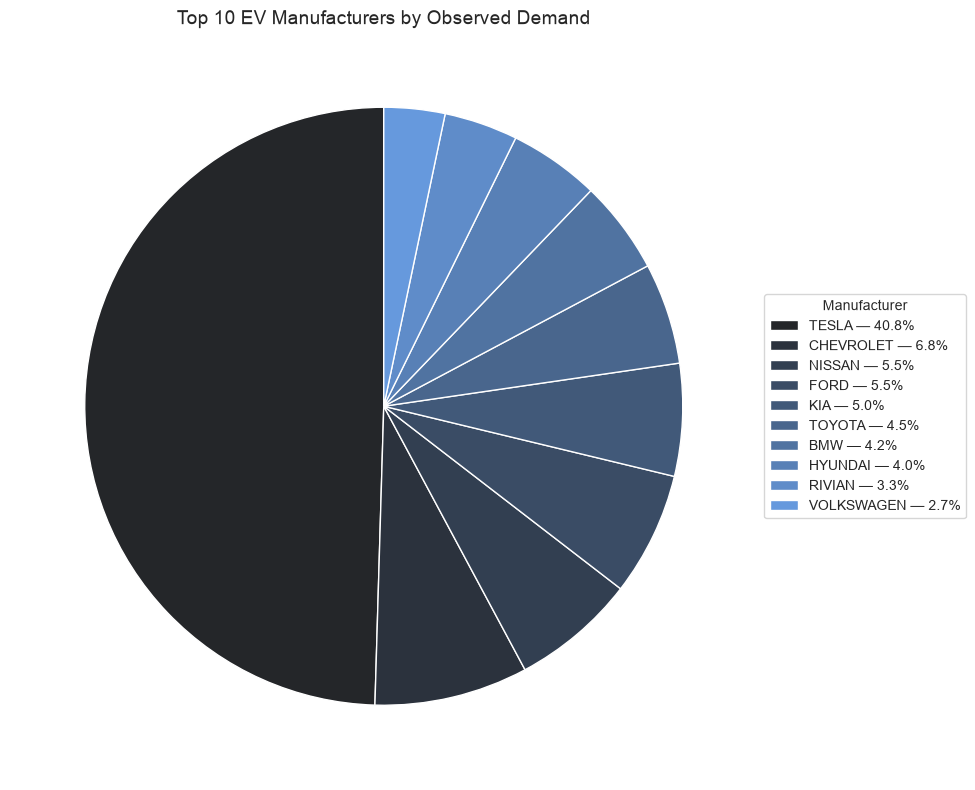

In [58]:
top_manufacturers = manufacturer_demand.head(10)
legend_labels = [
    f"{make} — {percentage:.1f}%"
    for make, percentage in zip(
        top_manufacturers["make"],
        top_manufacturers["market_share_pct"]
    )
]

# Colour theme
colors = sns.dark_palette("#69d", n_colors=10)

plt.figure(figsize=(10, 8))

plt.pie(
    top_manufacturers["vehicle_count"],
    startangle=90,
    colors=colors,
    wedgeprops={"edgecolor": "white", "linewidth": 1}
)

plt.title("Top 10 EV Manufacturers by Observed Demand", fontsize=14)

plt.legend(
    legend_labels,
    title="Manufacturer",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.tight_layout()
plt.show()

In [59]:
model_demand = (
    df_clean.groupby(["make", "model"])
    .size()
    .reset_index(name="vehicle_count")
    .sort_values("vehicle_count", ascending=False)
)
model_demand.head(15)

,make,model,vehicle_count
170,TESLA,MODEL Y,62979
167,TESLA,MODEL 3,38325
142,NISSAN,LEAF,13406
168,TESLA,MODEL S,7784
50,CHEVROLET,BOLT EV,7518
169,TESLA,MODEL X,7106
82,HYUNDAI,IONIQ 5,7053
69,FORD,MUSTANG MACH-E,6764
185,VOLKSWAGEN,ID.4,6312
154,RIVIAN,R1S,5504


/var/folders/vb/rvtgbc513wd4knzzjmsl970r0000gn/T/ipykernel_74438/2250761259.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


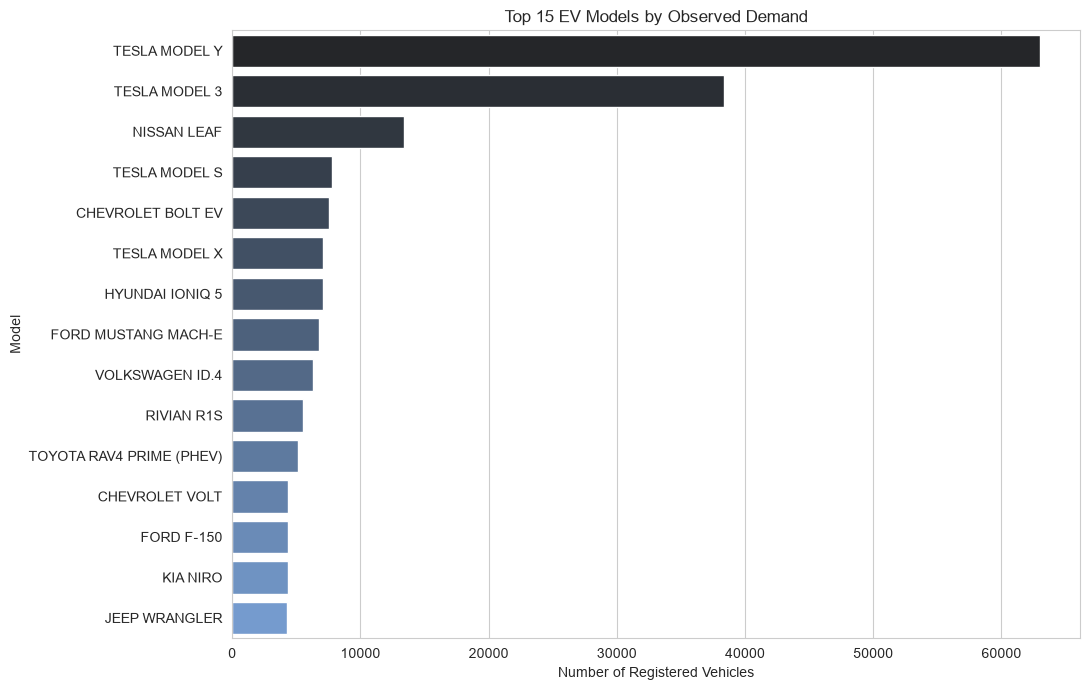

In [60]:
top_models = model_demand.head(15).copy()

top_models["model_label"] = (
    top_models["make"] + " " + top_models["model"]
)

plt.figure(figsize=(11, 7))

colors = sns.dark_palette("#69d", n_colors=15)

sns.barplot(
    data=top_models,
    x="vehicle_count",
    y="model_label",
    palette=colors
)

plt.title("Top 15 EV Models by Observed Demand")
plt.xlabel("Number of Registered Vehicles")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

In [61]:
county_demand = (
    df_clean.dropna(subset=["county"])
    .groupby("county")
    .size()
    .reset_index(name="vehicle_count")
    .sort_values("vehicle_count", ascending=False)
)
county_demand.head(10)

,county,vehicle_count
114,King,140130
207,Snohomish,36508
173,Pierce,24162
42,Clark,18060
227,Thurston,10617
116,Kitsap,10023
211,Spokane,8329
240,Whatcom,7205
20,Benton,4304
205,Skagit,3440


/var/folders/vb/rvtgbc513wd4knzzjmsl970r0000gn/T/ipykernel_74438/1036681949.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


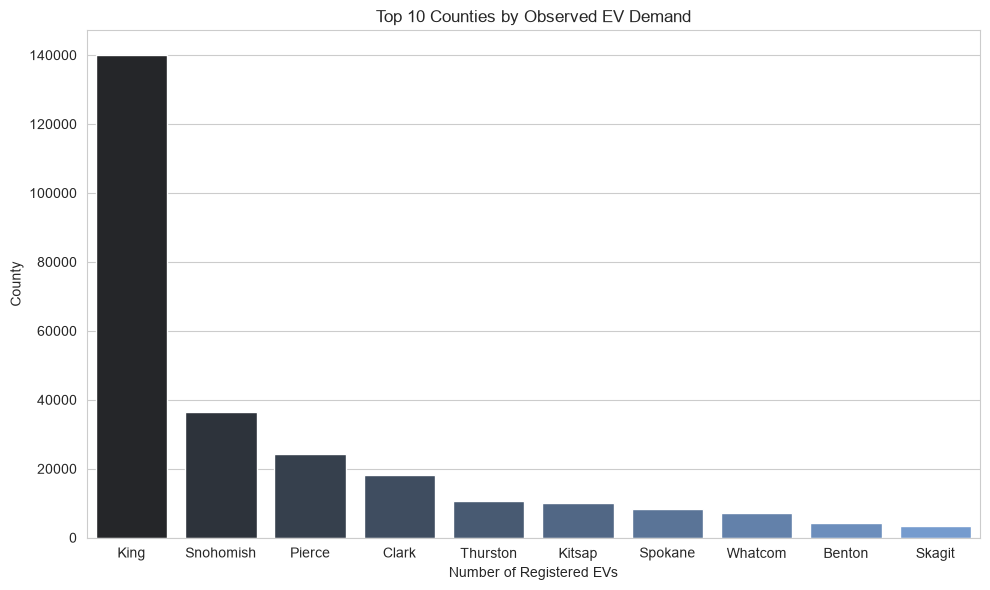

In [62]:
top_counties = county_demand.head(10)

colors = sns.dark_palette("#69d", n_colors=10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_counties,
    x="county",
    y="vehicle_count",
    palette=colors
)

plt.title("Top 10 Counties by Observed EV Demand")
plt.xlabel("Number of Registered EVs")
plt.ylabel("County")

plt.tight_layout()
plt.show()

In [63]:
df_range = df_clean.dropna(subset=["electric_range"]).copy()

In [64]:
df_range["electric_range"].describe()

count    101098.000000
mean        107.116392
std          96.952152
min           1.000000
25%          30.000000
50%          47.000000
75%         215.000000
max         337.000000
Name: electric_range, dtype: float64

In [65]:
range_bins = [
    -1,
    50,
    100,
    150,
    200,
    250,
    300,
    np.inf
]

range_labels = [
    "0–50",
    "51–100",
    "101–150",
    "151–200",
    "201–250",
    "251–300",
    "300+"
]

df_range["range_category"] = pd.cut(
    df_range["electric_range"],
    bins=range_bins,
    labels=range_labels
)

In [66]:
range_demand = (
    df_range.groupby("range_category", observed=False)
    .size()
    .reset_index(name="vehicle_count")
)

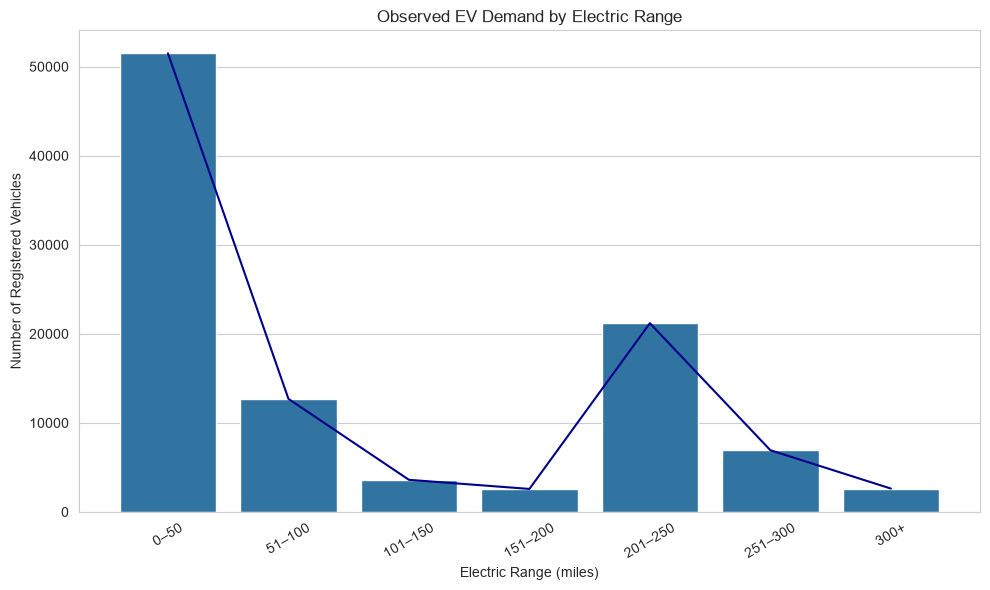

In [67]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=range_demand,
    x="range_category",
    y="vehicle_count"
)
sns.lineplot(x='range_category', y='vehicle_count', data=range_demand,
             color='darkblue')

plt.title("Observed EV Demand by Electric Range")
plt.xlabel("Electric Range (miles)")
plt.ylabel("Number of Registered Vehicles")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [68]:
range_by_type = (
    df_range.groupby("ev_type")["electric_range"]
    .agg(["count", "mean", "median", "min", "max"])
    .reset_index()
)

range_by_type

,ev_type,count,mean,median,min,max
0,Battery Electric Vehicle (BEV),45088,200.294469,215.0,29.0,337.0
1,Plug-in Hybrid Electric Vehicle (PHEV),56010,32.108124,32.0,1.0,153.0


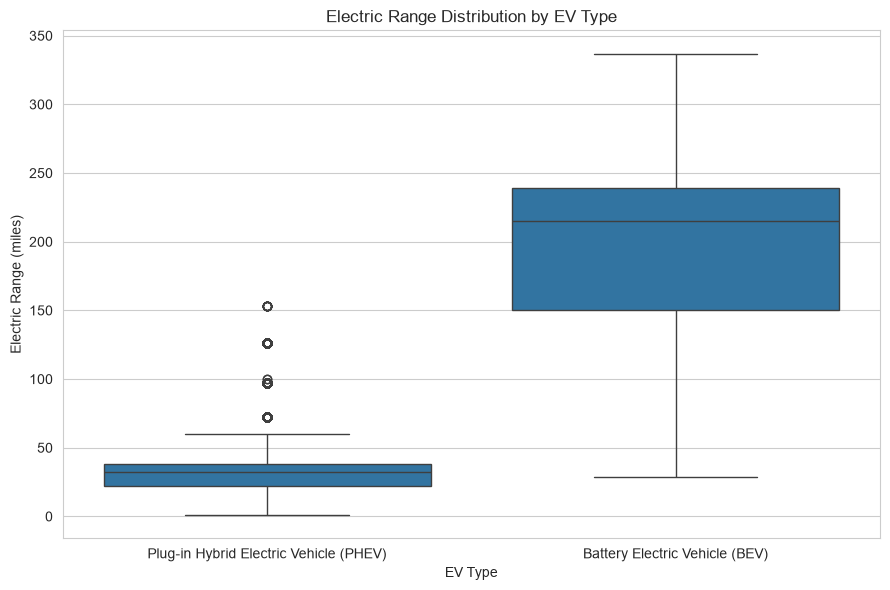

In [69]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_range,
    x="ev_type",
    y="electric_range"
)

plt.title("Electric Range Distribution by EV Type")
plt.xlabel("EV Type")
plt.ylabel("Electric Range (miles)")

plt.tight_layout()
plt.show()

In [70]:
range_by_year = (
    df_range.groupby("model_year")["electric_range"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

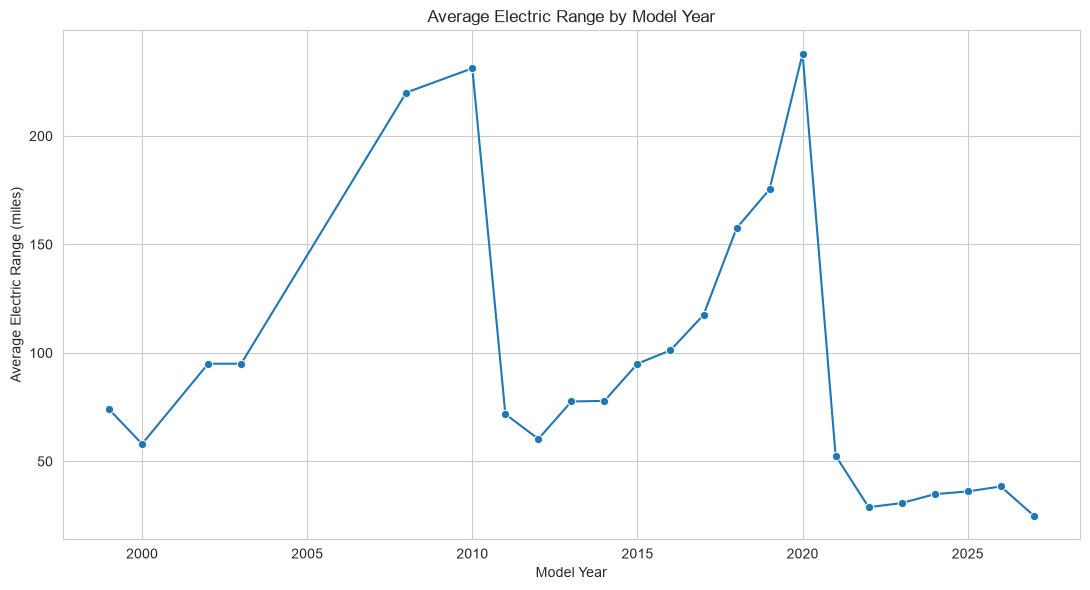

In [71]:
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=range_by_year,
    x="model_year",
    y="mean",
    marker="o"
)

plt.title("Average Electric Range by Model Year")
plt.xlabel("Model Year")
plt.ylabel("Average Electric Range (miles)")

plt.tight_layout()
plt.show()

In [72]:
manufacturer_range = (
    df_range.groupby("make")
    .agg(
        average_range=("electric_range", "mean"),
        median_range=("electric_range", "median"),
        vehicle_count=("electric_range", "count")
    )
    .sort_values("average_range", ascending=False)
)

In [73]:
manufacturer_range_filtered = manufacturer_range[
    manufacturer_range["vehicle_count"] >= 100
]
manufacturer_range_filtered.head(15)

,average_range,median_range,vehicle_count
make,,,
TESLA,241.473314,220.0,24001
POLESTAR,233.000000,233.0,199
CHEVROLET,152.122336,238.0,9760
VOLKSWAGEN,107.708253,125.0,1042
NISSAN,106.333051,84.0,9434
PORSCHE,91.616226,24.0,1097
FIAT,85.539310,87.0,725
AUDI,75.402661,23.0,2856
HYUNDAI,72.149324,33.0,1701


In [74]:
model_analysis = (
    df_range.groupby(["make", "model"])
    .agg(
        demand=("model", "size"),
        average_range=("electric_range", "mean"),
        model_year=("model_year", "mean")
    )
    .reset_index()
)

In [75]:
model_analysis.head()

,make,model,demand,average_range,model_year
0,ALFA ROMEO,TONALE,102,33.0,2024.029412
1,ASTON MARTIN,VALHALLA,1,6.0,2026.000000
2,AUDI,A3,523,16.0,2016.917782
3,AUDI,A7 E,10,24.0,2021.000000
4,AUDI,A8 E,5,17.0,2020.000000


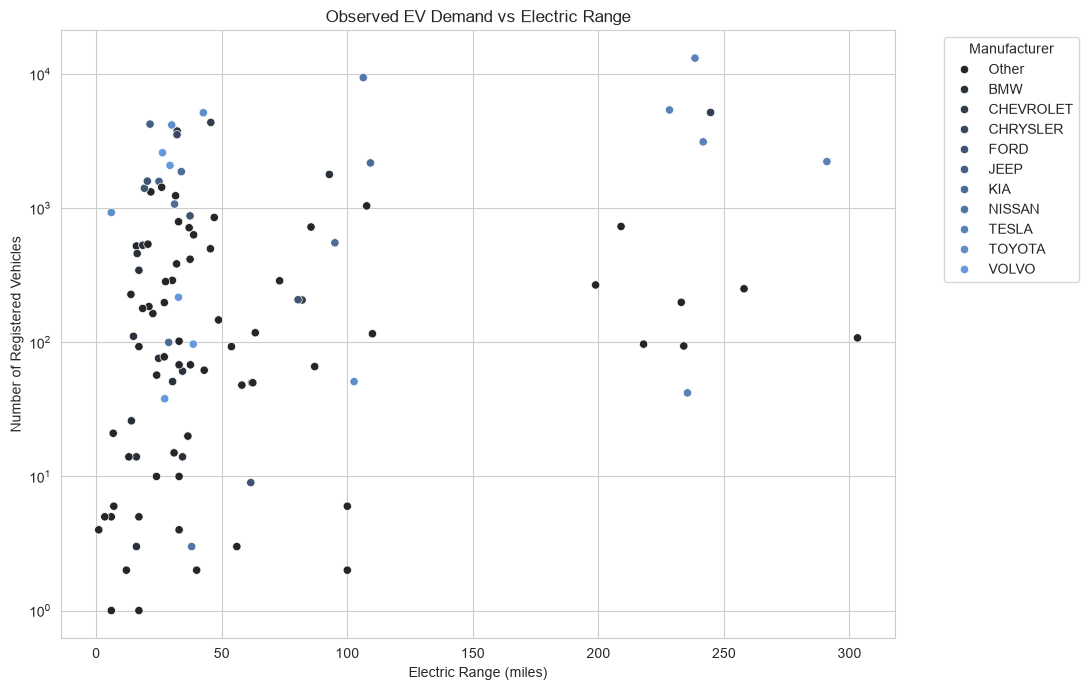

In [76]:
top_makes = (
    model_analysis.groupby("make")["demand"]
    .sum()
    .nlargest(10)
    .index
)

model_analysis["make_group"] = model_analysis["make"].where(
    model_analysis["make"].isin(top_makes),
    "Other"
)

plt.figure(figsize=(11, 7))
colors = sns.dark_palette("#69d", n_colors=11)

sns.scatterplot(
    data=model_analysis,
    x="average_range",
    y="demand",
    hue="make_group",
    alpha=1,
    palette=colors
)
plt.yscale("log")

plt.title("Observed EV Demand vs Electric Range")
plt.xlabel("Electric Range (miles)")
plt.ylabel("Number of Registered Vehicles")
plt.legend(
    title="Manufacturer",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [77]:
y = df_clean["electric_range"]

In [78]:
ml_data = df_clean.dropna(subset=["electric_range"]).copy()

In [79]:
features = [
    "model_year",
    "make",
    "model",
    "ev_type",
    "cafv_eligibility"
]

X = ml_data[features]
y = ml_data["electric_range"]

In [80]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [81]:
numeric_features = [
    "model_year"
]

categorical_features = [
    "make",
    "model",
    "ev_type",
    "cafv_eligibility"
]

In [82]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

In [83]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ]
)

In [84]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [85]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

In [86]:
linear_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['model_year','make','model','ev_type','cafv_eligibility']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated

In [87]:
y_pred_linear = linear_model.predict(X_test)

In [88]:
mae_linear = mean_absolute_error(
    y_test,
    y_pred_linear
)

rmse_linear = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_linear
    )
)

r2_linear = r2_score(
    y_test,
    y_pred_linear
)

print("Linear Regression")
print("MAE:", mae_linear)
print("RMSE:", rmse_linear)
print("R²:", r2_linear)

Linear Regression
MAE: 13.593077509509412
RMSE: 20.702236022969235
R²: 0.9547852040910607


In [89]:
random_forest = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1,
            max_depth=None
        ))
    ]
)

In [90]:
random_forest.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['model_year','make','model','ev_type','cafv_eligibility']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated

In [91]:
y_pred_rf = random_forest.predict(X_test)

In [92]:
mae_rf = mean_absolute_error(
    y_test,
    y_pred_rf
)

rmse_rf = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_rf
    )
)

r2_rf = r2_score(
    y_test,
    y_pred_rf
)

print("Random Forest")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R²:", r2_rf)

Random Forest
MAE: 1.169577782048883
RMSE: 5.63619592978244
R²: 0.9966486620255074


In [93]:
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mae_linear,
        mae_rf
    ],
    "RMSE": [
        rmse_linear,
        rmse_rf
    ],
    "R2": [
        r2_linear,
        r2_rf
    ]
})

model_results

,Model,MAE,RMSE,R2
0,Linear Regression,13.593078,20.702236,0.954785
1,Random Forest,1.169578,5.636196,0.996649


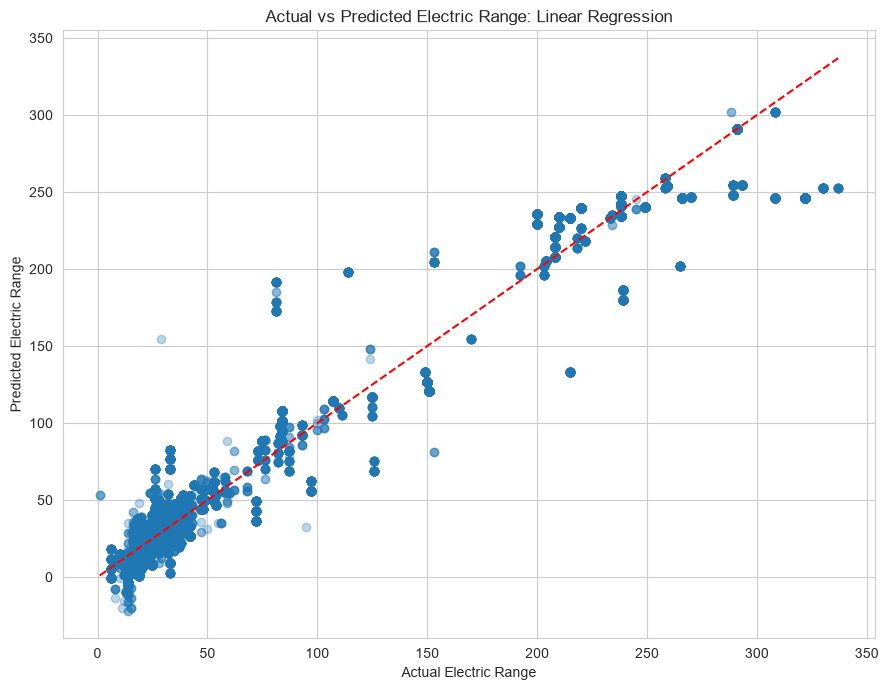

In [94]:
plt.figure(figsize=(9, 7))

plt.scatter(
    y_test,
    y_pred_linear,
    alpha=0.3
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Electric Range")
plt.ylabel("Predicted Electric Range")

plt.title("Actual vs Predicted Electric Range: Linear Regression")

plt.tight_layout()
plt.show()

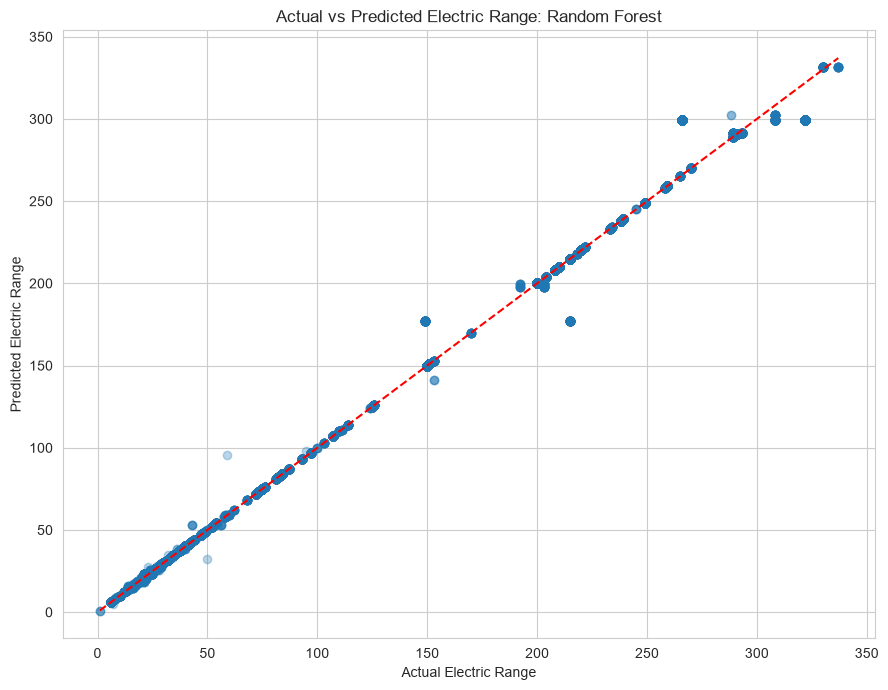

In [95]:
plt.figure(figsize=(9, 7))

plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.3
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Electric Range")
plt.ylabel("Predicted Electric Range")

plt.title("Actual vs Predicted Electric Range: Random Forest")

plt.tight_layout()
plt.show()

In [96]:
rf_preprocessor = random_forest.named_steps["preprocessor"]
rf_model = random_forest.named_steps["model"]

In [97]:
feature_names = rf_preprocessor.get_feature_names_out()

In [98]:
importance = rf_model.feature_importances_

In [99]:
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importance
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

In [100]:
feature_importance.head(20)

,feature,importance
147,cat__ev_type_Plug-in Hybrid Electric Vehicle (...,0.409950
146,cat__ev_type_Battery Electric Vehicle (BEV),0.335272
0,num__model_year,0.071538
93,cat__model_LEAF,0.056650
28,cat__make_NISSAN,0.055254
33,cat__make_TESLA,0.029562
56,cat__model_BOLT EV,0.007560
88,cat__model_I3,0.004426
149,cat__cafv_eligibility_Not eligible due to low ...,0.002996
148,cat__cafv_eligibility_Clean Alternative Fuel V...,0.002569


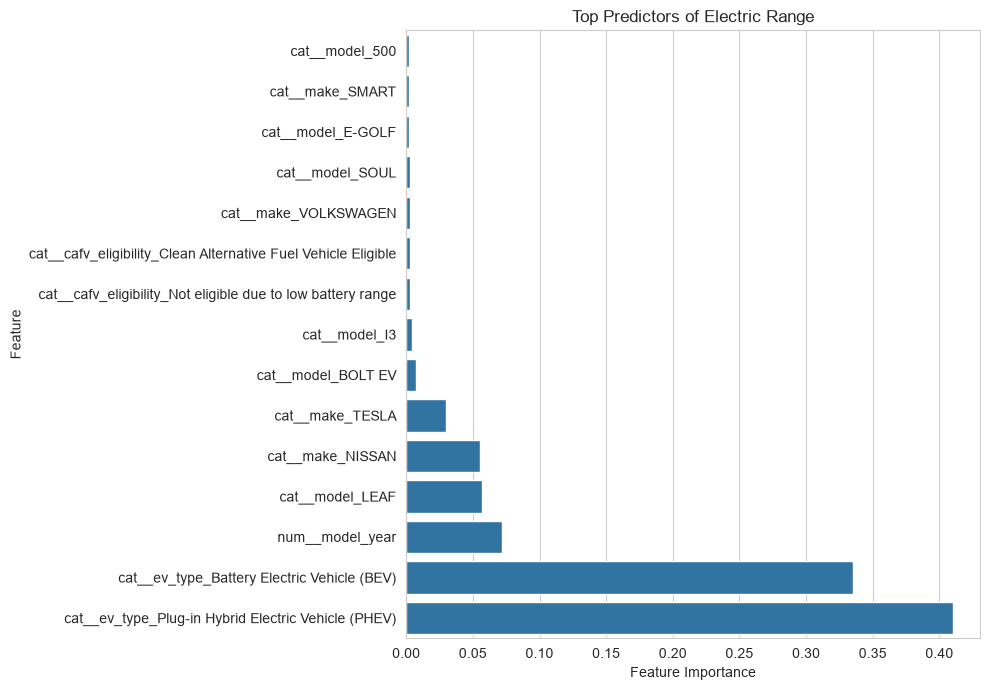

In [101]:
top_features = feature_importance.head(15).sort_values(
    "importance"
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="importance",
    y="feature"
)

plt.title("Top Predictors of Electric Range")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [102]:
example_vehicle = pd.DataFrame({
    "model_year": [2025],
    "make": ["TESLA"],
    "model": ["MODEL Y"],
    "ev_type": ["Battery Electric Vehicle (BEV)"],
    "cafv_eligibility": ["Clean Alternative Fuel Vehicle Eligible"]
})

In [103]:
predicted_range = random_forest.predict(example_vehicle)

print(
    "Predicted electric range:",
    round(predicted_range[0], 1),
    "miles"
)

Predicted electric range: 291.0 miles
